In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('Dataset_cleaned.csv', parse_dates=['date_added'])
print(df.shape)

(8787, 12)


In [2]:
rating_counts = df['rating'].value_counts()
print(rating_counts)

rating
TV-MA        3205
TV-14        2155
TV-PG         861
R             798
PG-13         490
TV-Y7         333
TV-Y          306
PG            287
TV-G          220
Not Rated      82
G              41
TV-Y7-FV        6
NC-17           3
Name: count, dtype: int64


In [3]:
def rating_to_audience(rating):
    kids = ['G', 'TV-G', 'TV-Y', 'TV-Y7', 'TV-Y7-FV']
    teens = ['PG', 'PG-13', 'TV-PG', 'TV-14']
    adults = ['R', 'NC-17', 'TV-MA']
    if rating in kids:
        return 'Kids'
    elif rating in teens:
        return 'Teens'
    elif rating in adults:
        return 'Adults'
    else:
        return 'Not Rated'

df['audience'] = df['rating'].apply(rating_to_audience)
print(df['audience'].value_counts())

audience
Adults       4006
Teens        3793
Kids          906
Not Rated      82
Name: count, dtype: int64


In [4]:
genre_split = df['listed_in'].str.split(',')
genre_exploded = genre_split.explode().str.strip()

print("Rows before:", len(df))
print("Rows after exploding:", len(genre_exploded))

Rows before: 8787
Rows after exploding: 19287


In [5]:
genre_counts = genre_exploded.value_counts()
print(genre_counts.head(15))

listed_in
International Movies        2752
Dramas                      2424
Comedies                    1673
International TV Shows      1348
Documentaries                869
Action & Adventure           859
TV Dramas                    761
Independent Movies           755
Children & Family Movies     641
Romantic Movies              616
Thrillers                    576
TV Comedies                  573
Crime TV Shows               469
Kids' TV                     448
Docuseries                   394
Name: count, dtype: int64


In [6]:
rating_by_type = df.groupby(['type', 'audience']).size().unstack(fill_value=0)
print(rating_by_type)

audience  Adults  Kids  Not Rated  Teens
type                                    
Movie       2861   442         78   2743
TV Show     1145   464          4   1050


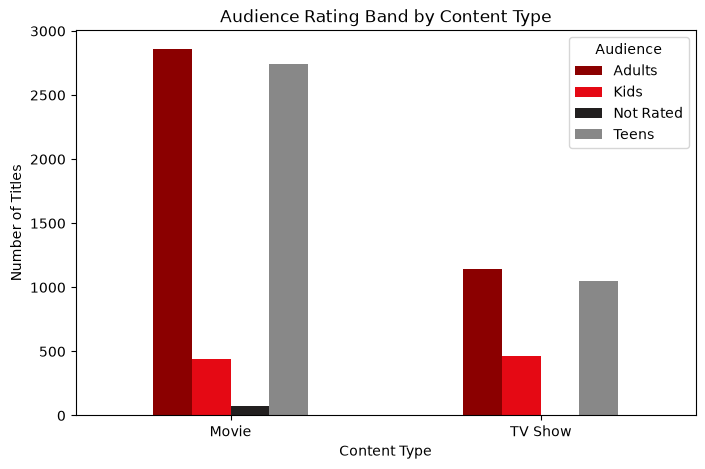

In [7]:
rating_by_type.plot(kind='bar', figsize=(8, 5), color=['#8B0000', '#E50914', '#221f1f', '#888888'])
plt.title('Audience Rating Band by Content Type')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')
plt.xticks(rotation=0)
plt.legend(title='Audience')
plt.show()

In [8]:
%pip install ipython nbformat

Note: you may need to restart the kernel to use updated packages.


In [9]:
import plotly.express as px

fig = px.bar(
    rating_by_type.reset_index().melt(id_vars='type', var_name='audience', value_name='count'),
    x='type', y='count', color='audience', barmode='group',
    color_discrete_map={'Adults': '#8B0000', 'Teens': '#E50914', 'Kids': '#221f1f', 'Not Rated': '#888888'},
    title='Audience Rating Band by Content Type (Interactive)'
)
fig.show()

## Task 5: Content Rating & Genre Analysis - Summary

### Objective
Examine content ratings and genres to understand audience targeting.

### Method Notes
- Ratings were grouped into four audience bands: Kids, Teens, Adults, and Not Rated (kept separate since its real audience is unknown).
- Genres (`listed_in`) often list multiple genres per title; the column was split so each genre is counted individually (8,787 titles → 19,287 genre entries, ~2.2 genres per title on average).
- In addition to static Matplotlib/Seaborn charts, an interactive Plotly chart (hover to see exact values) was created for the audience-rating comparison, directly addressing the task's request for interactive visualizations.

### Key Findings
1. **Adults is the largest audience band overall** (4,006 titles, ~46%), narrowly ahead of Teens (3,793, ~43%). Kids content is a much smaller share (906, ~10%).
2. **Movies split almost evenly between Adults and Teens** (2,861 vs 2,743), while **TV Shows lean more toward Adults** (1,145 vs 1,050) with almost no "Not Rated" titles.
3. **Most common genres:** International Movies (2,752), Dramas (2,424) and Comedies (1,673) dominate, reflecting Netflix's global, drama-and-comedy-heavy catalog.

### Business Insight
Netflix's catalog is weighted toward adult and teen audiences rather than young children, with Movies offering a broader age spread than TV Shows. Genre-wise, internationally-flavored drama and comedy content forms the backbone of the library, suggesting these categories are safe bets for continued investment, while kids' content remains comparatively underrepresented.